# Exploring Americans’ concern about data privacy

This beginner project uses Pew Research Center’s American Trends Panel Wave 127, collected May 15–21, 2023. I inspect the dataset and explore concern about government use of personal data.

The analysis uses unweighted counts and percentages to describe the sample. It does not reproduce Pew’s weighted estimates for all U.S. adults.

Sources: [Assigned article](https://www.pewresearch.org/short-reads/2023/10/18/key-findings-about-americans-and-data-privacy/) and [Wave 127 dataset](https://www.pewresearch.org/dataset/american-trends-panel-wave-127/).


### Importing the packages

I will first import the packages needed to read, explore, and plot the survey data.

In [3]:
import pandas as pd
import pyreadstat
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the dataset

I will load the Pew Research Center survey data from the SPSS file. I will also keep the information stored with the file, including variable descriptions and response labels.

In [ ]:
file_path = "W127_May23/W127_May23/ATP W127.sav"

data, information = pyreadstat.read_sav(file_path)

data.head()

### 3. Checking the size

Each row represents one respondent. Each column holds a response, background characteristic or administrative detail. Not all 147 columns are privacy questions.

In [7]:
print("Number of respondents:", data.shape[0])
print("Number of columns:", data.shape[1])
print("Respondent IDs are unique:", data["QKEY"].is_unique)

Number of respondents: 5101
Number of columns: 147
Respondent IDs are unique: True


### 4. Reading the dataset notes

The README identifies the survey weight and explains changes made to the released data. These notes should be read before trying to reproduce a published finding.

In [19]:
readme_path = "W127_May23/W127_May23/ATP W127 Readme.txt"

with open(readme_path, encoding="utf-8") as file:
    readme = file.read()

print(readme)

PEW RESEARCH CENTER
Wave 127 American Trends Panel 
Dates: May 15 - May 21, 2023
Mode: Web 
Sample: Subsample
Language: English and Spanish
N=5,101

***************************************************************************************************************************
NOTES

This dataset contains the variables corresponding to questions asked in the survey. It also contains administrative data, such as the main production weight and completion date. There are several types of additional variables that we can typically provide upon request, if they were created for published reporting: 
(1) Researcher-created variable(s) reflecting how we categorized responses to open-ended questions. We do not release verbatim answers to open-ended questions, in the interest of protecting panelist anonymity.
(2) Researcher-created variables needed to replicate published analysis (e.g., an index using several questions).
(3) Special weights needed to replicate published analysis. The main production

### 5. Understanding the column names

I will show all 147 variable names and their full descriptions to read the questions in the dataset.

In [10]:
variables = pd.DataFrame({
    "Variable": information.column_names,
    "Description": information.column_labels
})

# Show all rows
pd.set_option("display.max_rows", None)

# Show the full descriptions
pd.set_option("display.max_colwidth", None)

variables

,Variable,Description
0,QKEY,Unique ID
1,INTERVIEW_START_W127,Interview start time
2,INTERVIEW_END_W127,Interview end time
3,DEVICE_TYPE_W127,The device used in the latest access of the survey link
4,LANG_W127,LANG_W127. Language of interview
5,FORM_W127,Wave 127 form assignment
6,XTABLET_W127,XTABLET_W127. Flag to identify non-internet households that were provided a tablet
7,DIGCONF_W127,"DIGCONF_W127. Overall, how confident do you feel using computers, smartphones, or other electronic devices to do the things you need to do online?"
8,TECHHELP_W127,"TECHHELP_W127. Which of the following best describes you, even if neither is exactly right? When I get a new computer, smartphone, or other electronic device, I usually…"
9,SMARTPHONE_W127,SMARTPHONE_W127. Do you have a smartphone?


### 6. Finding privacy-related questions

I will search the descriptions for a few terms related to the assigned article. This gives me a starting list, rather than a final selection for analysis.

In [13]:
privacy_questions = variables[
    variables["Description"].str.contains(
        "privacy|personal information|password|data they collect|data it collects",
        case=False,
        na=False
    )
]

privacy_questions

,Variable,Description
31,PRIVFEEL_a_W127,"PRIVFEEL_a_W127. When you think about managing your privacy online, do you feel… Overwhelmed by figuring out what you need to do"
32,PRIVFEEL_b_W127,"PRIVFEEL_b_W127. When you think about managing your privacy online, do you feel… Skeptical that anything you do will make much difference"
33,PRIVFEEL_c_W127,"PRIVFEEL_c_W127. When you think about managing your privacy online, do you feel… Confident those who have access to your personal information will do what is right"
34,PRIVFEEL_d_W127,"PRIVFEEL_d_W127. When you think about managing your privacy online, do you feel… You trust yourself to make the right decisions about your personal information"
35,PRIVFEEL_e_W127,"PRIVFEEL_e_W127. When you think about managing your privacy online, do you feel… Like privacy is not that big of a deal to you"
36,PRIVWRY_a_W127,PRIVWRY_a_W127. How worried are you about each of the following? People stealing your identity or personal information
39,CYBCONF_W127,CYBCONF_W127. How confident are you in knowing what steps to take if your personal information is hacked or stolen online?
47,DKQ5_W127,DKQ5_W127. Which of the following passwords is the most secure?
51,DKQ10_W127,DKQ10_W127. Does the United States have a national privacy law that sets common standards for what companies can do with all data their products and services collect?
52,CONCERNCO_W127,CONCERNCO_W127. How concerned are you about how companies are using the data they collect about you?


### 7. Understanding the response codes

I will check the meaning of each response code for the question about government use of personal data before counting how people answered CONCERNGOV_W127.

In [14]:
question = "CONCERNGOV_W127"

# Show the question wording
print(information.column_names_to_labels[question])

# Get the meaning of each response code
response_labels = information.variable_value_labels[question]

# Put the codes and meanings into a table
code_meanings = pd.DataFrame(
    response_labels.items(),
    columns=["Code", "Meaning"]
)

code_meanings

CONCERNGOV_W127. How concerned are you about how the government is using the data it collects about you?


,Code,Meaning
0,1.0,Very concerned
1,2.0,Somewhat concerned
2,3.0,Not too concerned
3,4.0,Not at all concerned
4,99.0,Refused


### 8. Counting the responses
These are counts of people in the dataset. Both the codes and labels are shown for the question "**CONCERNGOV_W127**". dropna=False keeps any blank values visible.

In [15]:
response_counts = data[question].value_counts(dropna=False).sort_index()

response_table = response_counts.rename_axis("Code").reset_index(name="Count")
response_table["Response"] = response_table["Code"].map(
    information.variable_value_labels[question]
)

response_table

,Code,Count,Response
0,1.0,1590,Very concerned
1,2.0,2024,Somewhat concerned
2,3.0,1236,Not too concerned
3,4.0,226,Not at all concerned
4,99.0,25,Refused


### 9. Combining the concern categories

I will combine “very concerned” and “somewhat concerned” to see how many respondents expressed concern about government use of their data. These answers have codes 1 and 2.

In [16]:
# Select respondents who answered very or somewhat concerned
concerned = data[question].isin([1, 2])

# Count these respondents
concerned_count = concerned.sum()

print("Very or somewhat concerned:", concerned_count)

Very or somewhat concerned: 3614


### 10. Calculating the sample percentage

I will calculate the percentage of all respondents who answered “very concerned” or “somewhat concerned” to the question "**CONCERNGOV_W127**". The total includes respondents who refused or left the question blank.

In [17]:
total_respondents = len(data)

concerned_percent = concerned_count / total_respondents * 100

print("Very or somewhat concerned:", round(concerned_percent, 1), "%")

Very or somewhat concerned: 70.8 %


### 11. Showing the response counts

I will use a bar chart to compare how many respondents selected each answer. The chart shows sample counts without survey weights.

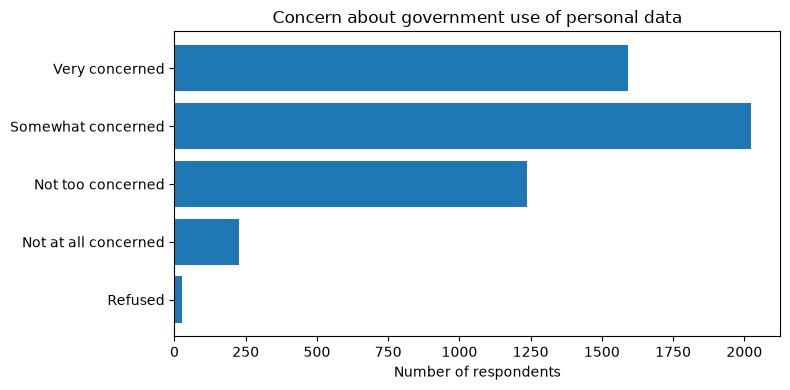

In [18]:
# Give any blank responses a readable label
chart_labels = response_table["Response"].fillna("Blank response")

plt.figure(figsize=(8, 4))

plt.barh(chart_labels, response_table["Count"])

plt.xlabel("Number of respondents")
plt.title("Concern about government use of personal data")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### What I found

For the question “How concerned are you about how the government is using the data it collects about you?”, 3,614 respondents chose very concerned or somewhat concerned. This is 70.8% of all 5,101 respondents, including refused and blank responses in the denominator.

This is an unweighted sample result. The keyword search gives a starting list of privacy questions and may miss relevant items with different wording. This project examines one question and does not establish causation or changes since 2019.
